# 05_tuning_randomsearch_v3.ipynb

## 목적
v3 데이터로 **LightGBM**과 **XGBoost**를 RandomizedSearchCV로 튜닝합니다.
두 모델 모두 같은 파이프라인(30% 샘플링 → RandomizedSearchCV → 전체 데이터 재학습)을 쓰기 때문에
한 노트북에서 함께 다룹니다. (베이지안 최적화 버전은 `06_tuning_optuna_v3.ipynb` 참고)

## 목차
1. 환경 세팅 및 데이터 로드
2. 30% 샘플링
3. RandomizedSearchCV 튜닝 — LightGBM
4. RandomizedSearchCV 튜닝 — XGBoost
5. 전체 데이터로 최종 모델 학습 및 평가
6. 피처 중요도 분석
7. v2 튜닝 결과 대비 성능 변화 확인
8. 결과 저장


## 1. 환경 세팅 및 데이터 로드

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import lightgbm as lgb
import xgboost as xgb
import time, os

from sklearn.model_selection import RandomizedSearchCV, train_test_split
from sklearn.metrics import (
    accuracy_score, roc_auc_score, f1_score,
    confusion_matrix, roc_curve, classification_report
)

plt.rc('font', family='Malgun Gothic')
plt.rcParams['axes.unicode_minus'] = False
sns.set_theme(style='whitegrid')
pd.options.display.float_format = '{:.4f}'.format
print('임포트 완료')

임포트 완료


In [2]:
X_train = pd.read_csv('../data/processed/X_train_v3.csv')
X_val   = pd.read_csv('../data/processed/X_val_v3.csv')
y_train = pd.read_csv('../data/processed/y_train_v3.csv').squeeze()
y_val   = pd.read_csv('../data/processed/y_val_v3.csv').squeeze()

# v2 튜닝 결과 로드 (비교용)
try:
    lgbm_v2_tuned = pd.read_csv('../results/lightgbm_tuned_v2.csv')
    lgbm_v2_auc = lgbm_v2_tuned['auc_roc'].values[0]
    print(f'LightGBM v2 튜닝 AUC (비교 기준): {lgbm_v2_auc}')
except FileNotFoundError:
    lgbm_v2_auc = None
    print('LightGBM v2 튜닝 결과 없음 — v3 베이스라인과 비교')

try:
    xgb_v2_tuned = pd.read_csv('../results/xgboost_tuned_v2.csv')
    xgb_v2_auc = xgb_v2_tuned['auc_roc'].values[0]
    print(f'XGBoost v2 튜닝 AUC (비교 기준): {xgb_v2_auc}')
except FileNotFoundError:
    xgb_v2_auc = None
    print('XGBoost v2 튜닝 결과 없음 — v3 베이스라인과 비교')

print(f'X_train: {X_train.shape}, X_val: {X_val.shape}')

LightGBM v2 튜닝 결과 없음 — v3 베이스라인과 비교
XGBoost v2 튜닝 결과 없음 — v3 베이스라인과 비교
X_train: (914921, 54), X_val: (228731, 54)


## 2. 30% 샘플링

In [3]:
# 전체 train 데이터의 30%만 사용해 튜닝 속도를 높입니다.
# stratify=y_train으로 이탈 비율을 유지합니다.
# 두 모델 모두 같은 샘플을 사용해 튜닝 조건을 동일하게 맞춥니다.
X_sample, _, y_sample, _ = train_test_split(
    X_train, y_train,
    train_size=0.3,
    random_state=42,
    stratify=y_train
)

print(f'샘플 데이터: {X_sample.shape} ({len(X_sample)/len(X_train)*100:.0f}%)')
print(f'샘플 이탈률: {y_sample.mean():.4f}')

샘플 데이터: (274476, 54) (30%)
샘플 이탈률: 0.5002


## 3. RandomizedSearchCV 튜닝 — LightGBM

In [4]:
lgbm_param_grid = {
    'num_leaves'       : [31, 63, 127, 255],
    'max_depth'        : [-1, 10, 15, 20],
    'learning_rate'    : [0.03, 0.05, 0.1],
    'n_estimators'     : [200, 300, 400],
    'subsample'        : [0.7, 0.8, 0.9],
    'colsample_bytree' : [0.7, 0.8, 0.9],
    'min_child_samples': [20, 50, 100]
}

lgbm_base_model = lgb.LGBMClassifier(random_state=42, n_jobs=-1, verbose=-1)

# n_iter=20: 전체 조합 중 20개만 무작위 탐색
# cv=2: 검증 fold 2개로 속도 최적화
lgbm_search = RandomizedSearchCV(
    estimator=lgbm_base_model,
    param_distributions=lgbm_param_grid,
    n_iter=20,
    scoring='roc_auc',
    cv=2,
    n_jobs=-1,
    random_state=42,
    verbose=1
)

start = time.time()
lgbm_search.fit(X_sample, y_sample)
lgbm_tuning_time = time.time() - start

lgbm_best_params = lgbm_search.best_params_
print(f'LightGBM 튜닝 소요 시간: {lgbm_tuning_time:.1f}초 (30% 샘플 기준)')
print('--- 최적 파라미터 ---')
print(lgbm_best_params)
print(f'CV 최고 AUC: {lgbm_search.best_score_:.4f}')

Fitting 2 folds for each of 20 candidates, totalling 40 fits


LightGBM 튜닝 소요 시간: 117.1초 (30% 샘플 기준)
--- 최적 파라미터 ---
{'subsample': 0.7, 'num_leaves': 127, 'n_estimators': 200, 'min_child_samples': 20, 'max_depth': 20, 'learning_rate': 0.03, 'colsample_bytree': 0.7}
CV 최고 AUC: 0.8460


## 4. RandomizedSearchCV 튜닝 — XGBoost

In [5]:
xgb_param_grid = {
    'max_depth'        : [4, 6, 8, 10],
    'learning_rate'    : [0.03, 0.05, 0.1],
    'n_estimators'     : [200, 300, 400],
    'subsample'        : [0.7, 0.8, 0.9],
    'colsample_bytree' : [0.7, 0.8, 0.9],
    'min_child_weight' : [1, 5, 10]
}

xgb_base_model = xgb.XGBClassifier(
    random_state=42, n_jobs=-1, verbosity=0,
    eval_metric='auc', use_label_encoder=False
)

# n_iter=20: 전체 조합 중 20개만 무작위 탐색
# cv=2: 검증 fold 2개로 속도 최적화
xgb_search = RandomizedSearchCV(
    estimator=xgb_base_model,
    param_distributions=xgb_param_grid,
    n_iter=20,
    scoring='roc_auc',
    cv=2,
    n_jobs=-1,
    random_state=42,
    verbose=1
)

start = time.time()
xgb_search.fit(X_sample, y_sample)
xgb_tuning_time = time.time() - start

xgb_best_params = xgb_search.best_params_
print(f'XGBoost 튜닝 소요 시간: {xgb_tuning_time:.1f}초 (30% 샘플 기준)')
print('--- 최적 파라미터 ---')
print(xgb_best_params)
print(f'CV 최고 AUC: {xgb_search.best_score_:.4f}')

Fitting 2 folds for each of 20 candidates, totalling 40 fits


XGBoost 튜닝 소요 시간: 104.6초 (30% 샘플 기준)
--- 최적 파라미터 ---
{'subsample': 0.7, 'n_estimators': 300, 'min_child_weight': 1, 'max_depth': 6, 'learning_rate': 0.03, 'colsample_bytree': 0.7}
CV 최고 AUC: 0.8461


## 5. 전체 데이터로 최종 모델 학습 및 평가

30% 샘플로 찾은 최적 파라미터를 전체 Train 데이터(100%)로 재학습합니다.

In [6]:
# LightGBM 최종 학습
final_lgbm = lgb.LGBMClassifier(**lgbm_best_params, random_state=42, n_jobs=-1, verbose=-1)
start = time.time()
final_lgbm.fit(
    X_train, y_train,
    eval_set=[(X_val, y_val)],
    callbacks=[lgb.early_stopping(50, verbose=False), lgb.log_evaluation(-1)]
)
lgbm_train_time = time.time() - start

lgbm_pred  = final_lgbm.predict(X_val)
lgbm_proba = final_lgbm.predict_proba(X_val)[:, 1]
lgbm_acc   = accuracy_score(y_val, lgbm_pred)
lgbm_auc   = roc_auc_score(y_val, lgbm_proba)
lgbm_f1    = f1_score(y_val, lgbm_pred)

print('--- LightGBM v3 RandomizedSearchCV 최종 성능 ---')
print(f'Accuracy : {lgbm_acc:.4f}')
print(f'AUC-ROC  : {lgbm_auc:.4f}')
print(f'F1-Score : {lgbm_f1:.4f}')
print(f'학습 시간 : {lgbm_train_time:.1f}초')

--- LightGBM v3 RandomizedSearchCV 최종 성능 ---
Accuracy : 0.7692
AUC-ROC  : 0.8486
F1-Score : 0.7727
학습 시간 : 15.4초


In [7]:
# XGBoost 최종 학습
final_xgb = xgb.XGBClassifier(
    **xgb_best_params, random_state=42, n_jobs=-1, verbosity=0,
    eval_metric='auc', use_label_encoder=False, early_stopping_rounds=50
)
start = time.time()
final_xgb.fit(X_train, y_train, eval_set=[(X_val, y_val)], verbose=False)
xgb_train_time = time.time() - start

xgb_pred  = final_xgb.predict(X_val)
xgb_proba = final_xgb.predict_proba(X_val)[:, 1]
xgb_acc   = accuracy_score(y_val, xgb_pred)
xgb_auc   = roc_auc_score(y_val, xgb_proba)
xgb_f1    = f1_score(y_val, xgb_pred)

print('--- XGBoost v3 RandomizedSearchCV 최종 성능 ---')
print(f'Accuracy : {xgb_acc:.4f}')
print(f'AUC-ROC  : {xgb_auc:.4f}')
print(f'F1-Score : {xgb_f1:.4f}')
print(f'학습 시간 : {xgb_train_time:.1f}초')

--- XGBoost v3 RandomizedSearchCV 최종 성능 ---
Accuracy : 0.7693
AUC-ROC  : 0.8478
F1-Score : 0.7722
학습 시간 : 57.3초


C:\workspace\2026project\customer_churn\venv\Lib\site-packages\seaborn\utils.py:61: UserWarning: Glyph 50976 (\N{HANGUL SYLLABLE YU}) missing from font(s) Arial.
  fig.canvas.draw()
C:\workspace\2026project\customer_churn\venv\Lib\site-packages\seaborn\utils.py:61: UserWarning: Glyph 51648 (\N{HANGUL SYLLABLE JI}) missing from font(s) Arial.
  fig.canvas.draw()
C:\workspace\2026project\customer_churn\venv\Lib\site-packages\seaborn\utils.py:61: UserWarning: Glyph 51060 (\N{HANGUL SYLLABLE I}) missing from font(s) Arial.
  fig.canvas.draw()
C:\workspace\2026project\customer_churn\venv\Lib\site-packages\seaborn\utils.py:61: UserWarning: Glyph 53448 (\N{HANGUL SYLLABLE TAL}) missing from font(s) Arial.
  fig.canvas.draw()


C:\workspace\2026project\customer_churn\venv\Lib\site-packages\seaborn\utils.py:61: UserWarning: Glyph 50696 (\N{HANGUL SYLLABLE YE}) missing from font(s) Arial.
  fig.canvas.draw()
C:\workspace\2026project\customer_churn\venv\Lib\site-packages\seaborn\utils.py:61: UserWarning: Glyph 52769 (\N{HANGUL SYLLABLE CEUG}) missing from font(s) Arial.
  fig.canvas.draw()
C:\workspace\2026project\customer_churn\venv\Lib\site-packages\seaborn\utils.py:61: UserWarning: Glyph 44050 (\N{HANGUL SYLLABLE GABS}) missing from font(s) Arial.
  fig.canvas.draw()
C:\workspace\2026project\customer_churn\venv\Lib\site-packages\seaborn\utils.py:61: UserWarning: Glyph 49892 (\N{HANGUL SYLLABLE SIL}) missing from font(s) Arial.
  fig.canvas.draw()
C:\workspace\2026project\customer_churn\venv\Lib\site-packages\seaborn\utils.py:61: UserWarning: Glyph 51228 (\N{HANGUL SYLLABLE JE}) missing from font(s) Arial.
  fig.canvas.draw()


C:\workspace\2026project\customer_churn\venv\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 50976 (\N{HANGUL SYLLABLE YU}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
C:\workspace\2026project\customer_churn\venv\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 51648 (\N{HANGUL SYLLABLE JI}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
C:\workspace\2026project\customer_churn\venv\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 51060 (\N{HANGUL SYLLABLE I}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
C:\workspace\2026project\customer_churn\venv\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 53448 (\N{HANGUL SYLLABLE TAL}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
C:\workspace\2026project\customer_churn\venv\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 50696 (\N{HANGUL SYLLABLE 

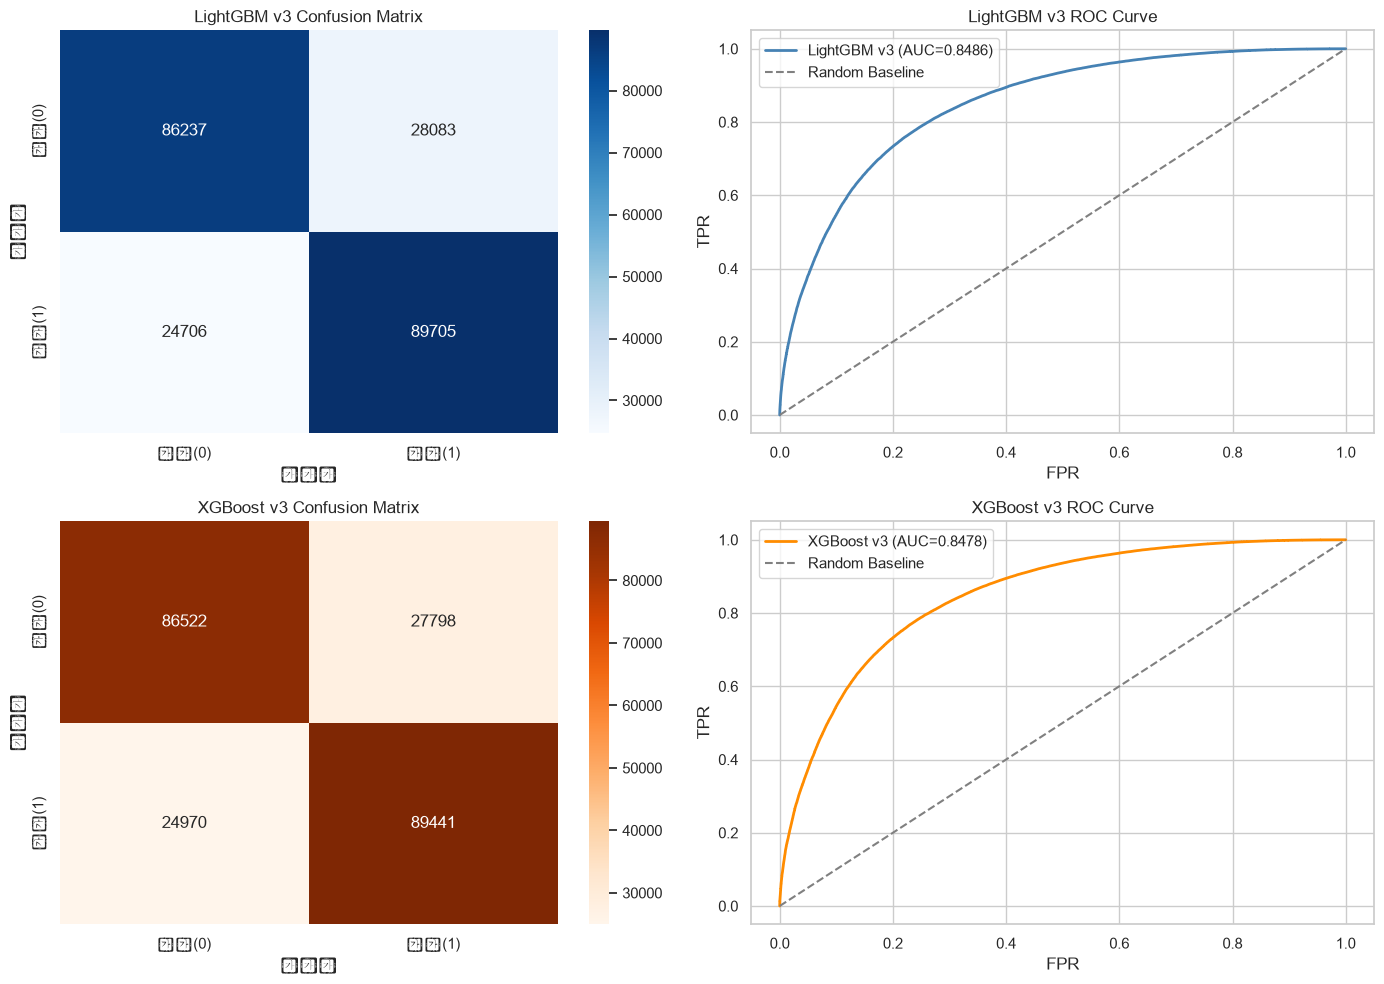

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for row, (name, pred, proba, auc_val, cmap, color) in enumerate([
    ('LightGBM', lgbm_pred, lgbm_proba, lgbm_auc, 'Blues', 'steelblue'),
    ('XGBoost',  xgb_pred,  xgb_proba,  xgb_auc,  'Oranges', 'darkorange'),
]):
    cm = confusion_matrix(y_val, pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap=cmap,
                xticklabels=['유지(0)','이탈(1)'], yticklabels=['유지(0)','이탈(1)'], ax=axes[row, 0])
    axes[row, 0].set_title(f'{name} v3 Confusion Matrix')
    axes[row, 0].set_ylabel('실제값'); axes[row, 0].set_xlabel('예측값')

    fpr, tpr, _ = roc_curve(y_val, proba)
    axes[row, 1].plot(fpr, tpr, color=color, lw=2, label=f'{name} v3 (AUC={auc_val:.4f})')
    axes[row, 1].plot([0,1],[0,1], linestyle='--', color='gray', label='Random Baseline')
    axes[row, 1].set_title(f'{name} v3 ROC Curve')
    axes[row, 1].set_xlabel('FPR'); axes[row, 1].set_ylabel('TPR')
    axes[row, 1].legend()

plt.tight_layout(); plt.show()

## 6. 피처 중요도 분석

C:\Users\09048\AppData\Local\Temp\ipykernel_19908\1566190510.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='importance', y='feature', data=lgbm_imp.head(20), ax=axes[0], palette='Blues_r')


C:\Users\09048\AppData\Local\Temp\ipykernel_19908\1566190510.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='importance', y='feature', data=xgb_imp.head(20), ax=axes[1], palette='Oranges_r')


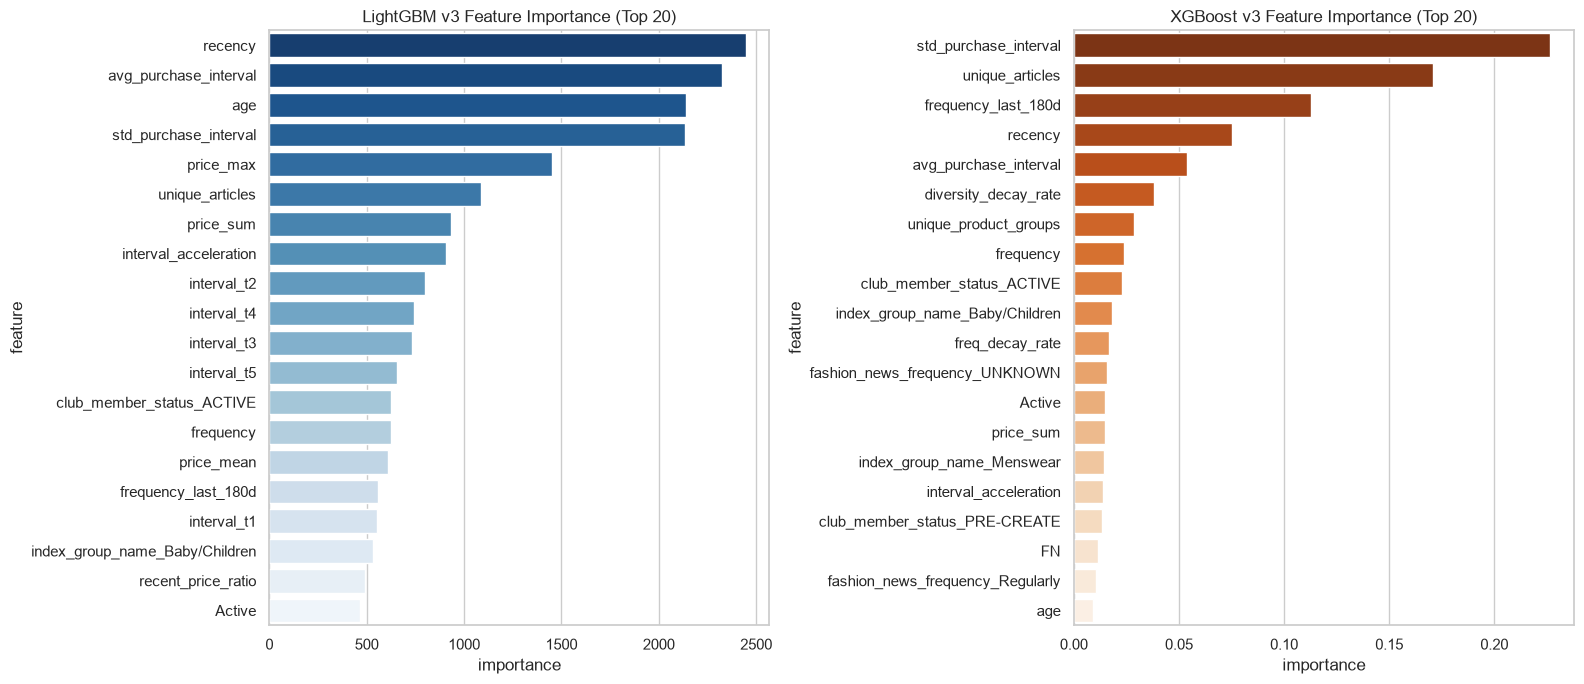

--- 시퀀스 피처(interval_t1~t5) 순위: LightGBM ---
 rank     feature  importance
    9 interval_t2         800
   10 interval_t4         744
   11 interval_t3         731
   12 interval_t5         656
   17 interval_t1         551

--- 시퀀스 피처(interval_t1~t5) 순위: XGBoost ---
 rank     feature  importance
   24 interval_t5      0.0058
   25 interval_t2      0.0054
   26 interval_t4      0.0050
   27 interval_t3      0.0047
   32 interval_t1      0.0038


In [9]:
lgbm_imp = pd.DataFrame({
    'feature'   : X_train.columns,
    'importance': final_lgbm.feature_importances_
}).sort_values('importance', ascending=False).reset_index(drop=True)
lgbm_imp['rank'] = lgbm_imp.index + 1

xgb_imp = pd.DataFrame({
    'feature'   : X_train.columns,
    'importance': final_xgb.feature_importances_
}).sort_values('importance', ascending=False).reset_index(drop=True)
xgb_imp['rank'] = xgb_imp.index + 1

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
sns.barplot(x='importance', y='feature', data=lgbm_imp.head(20), ax=axes[0], palette='Blues_r')
axes[0].set_title('LightGBM v3 Feature Importance (Top 20)')

sns.barplot(x='importance', y='feature', data=xgb_imp.head(20), ax=axes[1], palette='Oranges_r')
axes[1].set_title('XGBoost v3 Feature Importance (Top 20)')

plt.tight_layout(); plt.show()

# 시퀀스 피처 순위 확인
seq_cols = ['interval_t1','interval_t2','interval_t3','interval_t4','interval_t5']
print('--- 시퀀스 피처(interval_t1~t5) 순위: LightGBM ---')
print(lgbm_imp[lgbm_imp['feature'].isin(seq_cols)][['rank','feature','importance']].to_string(index=False))
print('\n--- 시퀀스 피처(interval_t1~t5) 순위: XGBoost ---')
print(xgb_imp[xgb_imp['feature'].isin(seq_cols)][['rank','feature','importance']].to_string(index=False))

## 7. v2 튜닝 결과 대비 성능 변화 확인

In [10]:
def compare_with_v2(model_name, v3_auc, v2_auc):
    print(f'--- {model_name} v2 튜닝 vs v3 최종 비교 ---')
    if v2_auc is None:
        print('v2 결과가 없어 v3 베이스라인과 비교하세요.')
        return
    improvement = v3_auc - v2_auc
    print(f'v2 튜닝 AUC : {v2_auc:.4f}')
    print(f'v3 최종 AUC : {v3_auc:.4f}')
    print(f'개선폭       : {improvement:+.4f}')
    if improvement < 0.003:
        print('→ 시퀀스 피처 추가에도 성능 향상이 미미합니다.')
    else:
        print('→ 시퀀스 피처가 성능 개선에 기여했습니다.')

compare_with_v2('LightGBM', lgbm_auc, lgbm_v2_auc)
print()
compare_with_v2('XGBoost', xgb_auc, xgb_v2_auc)

--- LightGBM v2 튜닝 vs v3 최종 비교 ---
v2 결과가 없어 v3 베이스라인과 비교하세요.

--- XGBoost v2 튜닝 vs v3 최종 비교 ---
v2 결과가 없어 v3 베이스라인과 비교하세요.


## 8. 결과 저장

In [11]:
os.makedirs('../results', exist_ok=True)

result = pd.DataFrame([
    {
        'model'      : 'LightGBM_v3_randomsearch',
        'accuracy'   : round(lgbm_acc, 4),
        'auc_roc'    : round(lgbm_auc, 4),
        'f1_score'   : round(lgbm_f1, 4),
        'train_time' : round(lgbm_train_time, 1),
        'tuning_time': round(lgbm_tuning_time, 1),
        'v2_auc'     : lgbm_v2_auc,
        'improvement': round(lgbm_auc - lgbm_v2_auc, 4) if lgbm_v2_auc else None
    },
    {
        'model'      : 'XGBoost_v3_randomsearch',
        'accuracy'   : round(xgb_acc, 4),
        'auc_roc'    : round(xgb_auc, 4),
        'f1_score'   : round(xgb_f1, 4),
        'train_time' : round(xgb_train_time, 1),
        'tuning_time': round(xgb_tuning_time, 1),
        'v2_auc'     : xgb_v2_auc,
        'improvement': round(xgb_auc - xgb_v2_auc, 4) if xgb_v2_auc else None
    }
])

result.to_csv('../results/tuning_randomsearch_v3.csv', index=False)
print('결과 저장 완료: ../results/tuning_randomsearch_v3.csv')
print(result.to_string(index=False))

결과 저장 완료: ../results/tuning_randomsearch_v3.csv
                   model  accuracy  auc_roc  f1_score  train_time  tuning_time v2_auc improvement
LightGBM_v3_randomsearch    0.7692   0.8486    0.7727     15.4000     117.1000   None        None
 XGBoost_v3_randomsearch    0.7693   0.8478    0.7722     57.3000     104.6000   None        None
